In [1]:
# Import modules
import numpy as np
import math
import random
import matplotlib.pyplot as plt

In [2]:
lim1 = np.deg2rad(170)
lim2 = np.deg2rad(120)
lim3 = np.deg2rad(170)
lim4 = np.deg2rad(120)
lim5 = np.deg2rad(170)
lim6 = np.deg2rad(120)
lim7 = np.deg2rad(175)

constraints = (np.array([-lim1 , -lim2 , -lim3 , -lim4 , -lim5 , -lim6, -lim7]),
               np.array([ lim1  , lim2 ,  lim3 ,  lim4 ,  lim5 ,  lim6,  lim7]))

d2 = d4 = d4 = d6 = 0.01
d1 = 0.34
d3 = 0.4
d5 = 0.4
d7 = 0.126

In [3]:
def getTransformMatrix(theta, d, a, alpha):
    T = np.array([[np.cos(theta) , -np.sin(theta)*np.cos(alpha) ,  np.sin(theta)*np.sin(alpha) , a*np.cos(theta)],
                  [np.sin(theta) ,  np.cos(theta)*np.cos(alpha) , -np.cos(theta)*np.sin(alpha) , a*np.sin(theta)],
                  [0             ,  np.sin(alpha)               ,  np.cos(alpha)               , d              ],
                  [0             ,  0                           ,  0                           , 1              ]
                 ])
    return T

def get_end_tip_position(params):
    # Create the transformation matrices for the respective joints
    t_00 = np.array([[1,0,0,0],[0,1,0,0],[0,0,1,0],[0,0,0,1]])
    t_01 = getTransformMatrix(params[0] , d1  , 0 , -np.pi/2)
    t_12 = getTransformMatrix(params[1] , d2  , 0 ,  np.pi/2)
    t_23 = getTransformMatrix(params[2] , d3  , 0 ,  np.pi/2)
    t_34 = getTransformMatrix(params[3] , d4  , 0 , -np.pi/2)
    t_45 = getTransformMatrix(params[4] , d5  , 0 , -np.pi/2)
    t_56 = getTransformMatrix(params[5] , d6  , 0 ,  np.pi/2)
    t_67 = getTransformMatrix(params[6] , d7  , 0 ,        0)

    # Get the overall transformation matrix
    end_tip_m = t_00.dot(t_01).dot(t_12).dot(t_23).dot(t_34).dot(t_45).dot(t_56).dot(t_67)

    # The coordinates of the end tip are the 3 upper entries in the 4th column
    pos = np.array([end_tip_m[0,3],end_tip_m[1,3],end_tip_m[2,3]])
    return pos

def get_nth_position(params,n):
    # Create the transformation matrices for the respective joints
    t_00 = np.array([[1,0,0,0],[0,1,0,0],[0,0,1,0],[0,0,0,1]])
    t_01 = getTransformMatrix(params[0] , d1  , 0 , -np.pi/2)
    t_12 = getTransformMatrix(params[1] , d2  , 0 ,  np.pi/2)
    t_23 = getTransformMatrix(params[2] , d3  , 0 ,  np.pi/2)
    t_34 = getTransformMatrix(params[3] , d4  , 0 , -np.pi/2)
    t_45 = getTransformMatrix(params[4] , d5  , 0 , -np.pi/2)
    t_56 = getTransformMatrix(params[5] , d6  , 0 ,  np.pi/2)
    t_67 = getTransformMatrix(params[6] , d7  , 0 ,        0)

    if n==0:
        end_tip_m = t_00#.dot(t_01).dot(t_12).dot(t_23).dot(t_34).dot(t_45).dot(t_56).dot(t_67)
    elif n==1:
        end_tip_m = t_00.dot(t_01)#.dot(t_12).dot(t_23).dot(t_34).dot(t_45).dot(t_56).dot(t_67)
    elif n==2:
        end_tip_m = t_00.dot(t_01).dot(t_12)#.dot(t_23).dot(t_34).dot(t_45).dot(t_56).dot(t_67)
    elif n==3:
        end_tip_m = t_00.dot(t_01).dot(t_12).dot(t_23)#.dot(t_34).dot(t_45).dot(t_56).dot(t_67)
    elif n==4:
        end_tip_m = t_00.dot(t_01).dot(t_12).dot(t_23).dot(t_34)#.dot(t_45).dot(t_56).dot(t_67)
    elif n==5:
        end_tip_m = t_00.dot(t_01).dot(t_12).dot(t_23).dot(t_34).dot(t_45)#.dot(t_56).dot(t_67)
    elif n==6:
        end_tip_m = t_00.dot(t_01).dot(t_12).dot(t_23).dot(t_34).dot(t_45).dot(t_56)#.dot(t_67)
    elif n==7:
        end_tip_m = t_00.dot(t_01).dot(t_12).dot(t_23).dot(t_34).dot(t_45).dot(t_56).dot(t_67)#
    else:
        print('no more tf')
        
    # The coordinates of the end tip are the 3 upper entries in the 4th column
    pos = np.array([end_tip_m[0,3],end_tip_m[1,3],end_tip_m[2,3]])
    return pos

# Plot the resulting joint configuration and end pose.
def visualize_config(sol, target, alg):
    fig = plt.figure(figsize=(8, 8))
    ax = fig.add_subplot(projection='3d')
    for i in range(7):
        point = get_nth_position(sol,i)
        point_n = get_nth_position(sol,i+1)
        print(f"{i}: {point}")
        x,y,z = [point[0],point_n[0]], [point[1],point_n[1]], [point[2],point_n[2]]
        ax.scatter(x, y, z, c='red', s=100)
        ax.plot(x, y, z, color='black',linewidth=4)
        if i==6:
            ax.scatter(point_n[0], point_n[1], point_n[2], c='red', s=120)

    ax.scatter(0,0,0)
    ax.scatter(target[0],target[1],target[2],c='green', s=260)

    fig.suptitle('Arm Visualization via {}'.format(alg))
    ax.set_xlabel('X Label')
    ax.set_ylabel('Y Label', fontsize=10)
    ax.set_zlabel('Z Label', fontsize=10)
    plt.show()

In [4]:
constraints[1]

array([2.96705973, 2.0943951 , 2.96705973, 2.0943951 , 2.96705973,
       2.0943951 , 3.05432619])

## Optimize With Simulated Annealing (SA)

Iteration 29785: T=0.702, Current Cost=0.008, Best Cost=0.008
Target position: 
[-0.09749897  0.41043537  0.3017571 ]


Best Solution: [-1.05227163 -0.76081387 -0.62654389  1.80686609  0.95887896 -2.04996018
 -0.15306481], Cost: 0.008145138586523108

Position with predicted angles:
 [-0.0952  0.4038  0.3059]


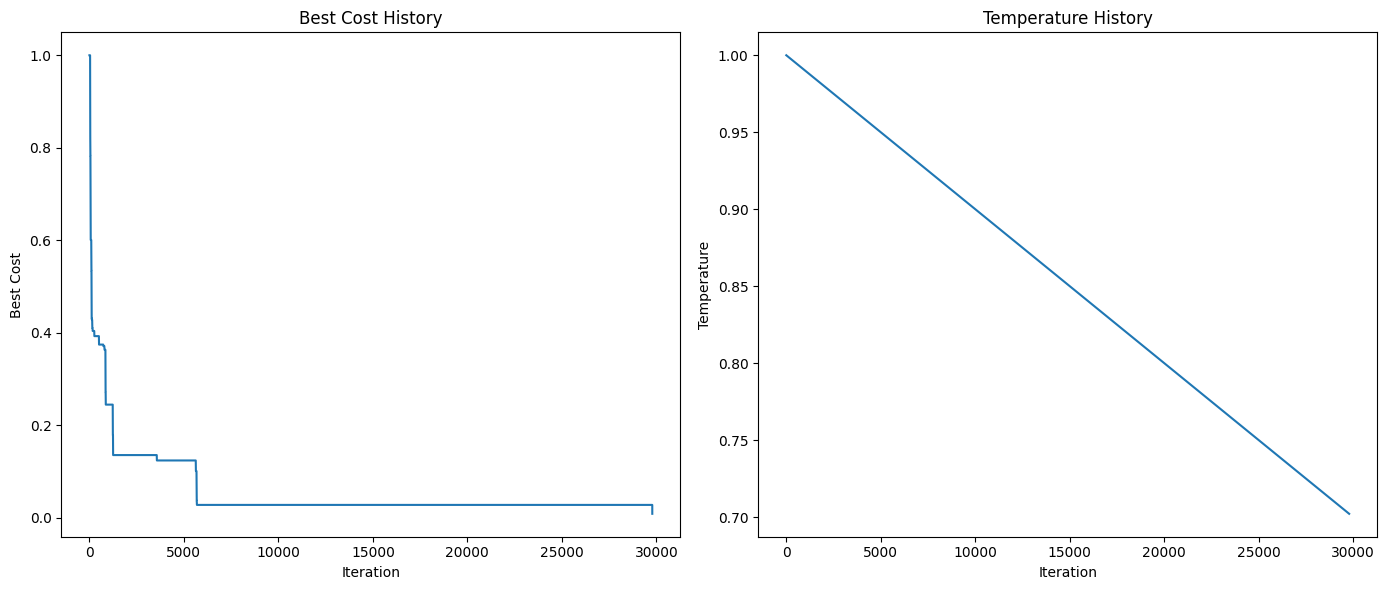

0: [0 0 0]
1: [0.   0.   0.34]
2: [0.00868551 0.00495599 0.34      ]
3: [-0.12800298  0.24450631  0.62971003]
4: [-0.13714346  0.2441802   0.62566709]
5: [-0.02019719  0.49934722  0.34068751]
6: [-0.0126453   0.49323652  0.33831512]


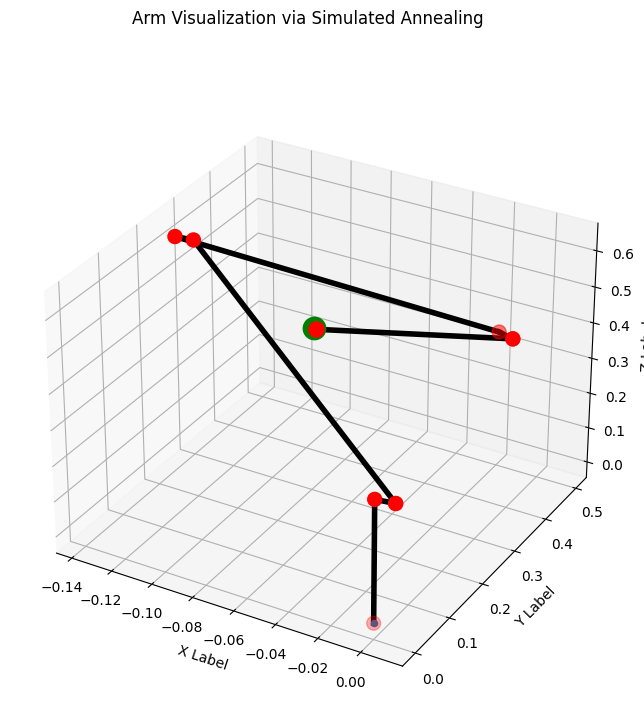

In [5]:
def objective_function(joint_angles, target_position):
    # Compute the current position of the end-effector based on joint angles
    current_position = get_end_tip_position(joint_angles)  # Placeholder value
    # Calculate the Euclidean distance to the target position
    distance = np.linalg.norm(current_position - target_position)
    return distance

def simulated_annealing_for_ik(target_position, bounds, initial_temperature, n_iterations, step_size):
    num_joints = len(bounds)
    current_solution = np.array([random.uniform(low, high) for low, high in bounds])
    current_cost = objective_function(current_solution, target_position)
    best_solution, best_cost = current_solution.copy(), current_cost

    # Initialize history tracking
    cost_history = []
    temperature_history = []
    
    for i in range(n_iterations):
        fraction = i / float(n_iterations)
        T = max(0.01, min(1, 1 - fraction))  # Cooling schedule
        
        # Generate a neighbor solution (ensure it respects joint limits)
        candidate_solution = current_solution + np.random.uniform(-step_size, step_size, num_joints)
        candidate_solution = np.clip(candidate_solution, constraints[0], constraints[1])
        candidate_cost = objective_function(candidate_solution, target_position)
        
        if candidate_cost < best_cost or math.exp((current_cost - candidate_cost) / T) > random.random():
            current_solution, current_cost = candidate_solution, candidate_cost
            if candidate_cost < best_cost:
                best_solution, best_cost = candidate_solution.copy(), candidate_cost

        if n_iterations - i == 10:
            print("Last 10 iterations:\n")
        elif n_iterations - i < 10:
            print(f"Iteration {i}: T={T:.3f}, Current Cost={current_cost:.3f}, Best Cost={best_cost:.3f}")
     
        # Update history
        cost_history.append(best_cost)
        temperature_history.append(T)
        
        if candidate_cost < 0.02:
            print(f"Iteration {i}: T={T:.3f}, Current Cost={current_cost:.3f}, Best Cost={best_cost:.3f}")
            break
    return best_solution, best_cost, cost_history, temperature_history

# Parameters for the IK problem
# Target position for the end-effector
#target_position = np.array([-0.00232187, -0.25024734,  0.79152821])
x, y, z = np.random.uniform(-0.5,0.5), np.random.uniform(-0.5,0.5), np.random.uniform(0.05,0.8)
target_position = np.array([x,y,z])

bounds = [(constraints[0][i], constraints[1][i]) for i in range(7)] 
initial_temperature = 0.6
n_iterations = 100000
step_size = 0.1

# Solving the IK problem
best_solution, best_cost, cost_history, temperature_history = simulated_annealing_for_ik(target_position, bounds, initial_temperature, n_iterations, step_size)
print(f"Target position: \n{target_position}\n")
print(f"\nBest Solution: {best_solution}, Cost: {best_cost}\n")
print(f"Position with predicted angles:\n {get_end_tip_position(best_solution).round(4)}")

# Visualize the results
plt.figure(figsize=(14, 6))
plt.subplot(1, 2, 1)
plt.plot(cost_history)
plt.title('Best Cost History')
plt.xlabel('Iteration')
plt.ylabel('Best Cost')

plt.subplot(1, 2, 2)
plt.plot(temperature_history)
plt.title('Temperature History')
plt.xlabel('Iteration')
plt.ylabel('Temperature')

plt.tight_layout()
plt.show()


visualize_config(best_solution, target_position, 'Simulated Annealing')
plt.show()

-
-
-